<center><h1>Tong_Stephanie_HW5</h1></center>
<br>
<br>

Name: Stephanie Tong
<br>
Github Username: tongstep
<br>
USC ID: 2614015757

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [3]:
df = pd.read_csv("data/diagnosis.data", sep="\t", header=None, encoding="utf-16", names=["Temperature","Nausea","Lumbar_pain","Urine_pushing","Micturition_pains","Burning_urethra","Inflammation","Nephritis"])
df.head()

,Temperature,Nausea,Lumbar_pain,Urine_pushing,Micturition_pains,Burning_urethra,Inflammation,Nephritis
0,"35,5",no,yes,no,no,no,no,no
1,"35,9",no,no,yes,yes,yes,yes,no
2,"35,9",no,yes,no,no,no,no,no
3,"36,0",no,no,yes,yes,yes,yes,no
4,"36,0",no,yes,no,no,no,no,no


### (b) Build a decision tree

In [4]:
df["Temperature"] = df["Temperature"].str.replace(",",".").astype(float)

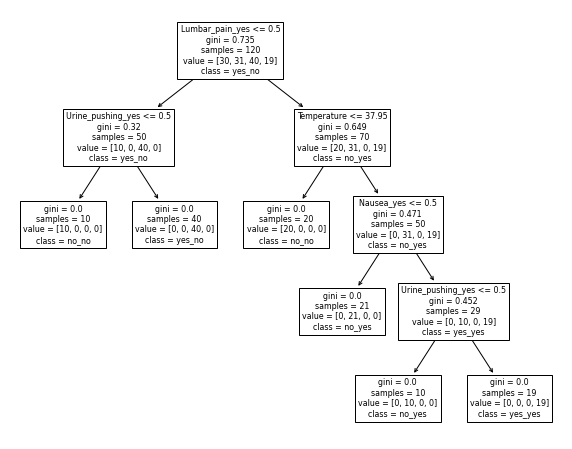

In [5]:
X = df.drop(["Inflammation","Nephritis"],axis=1)
y = df["Inflammation"] + "_" + df["Nephritis"]

X = pd.get_dummies(X, drop_first=True)

dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X,y)

plt.figure(figsize=(10,8))
plot_tree(dtree, feature_names=X.columns, class_names=dtree.classes_)
plt.show()

### (c) Convert the decision rules

In [6]:
def tree_to_pseudo(tree, feature_names):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] for i in tree.tree_.feature]
    value = tree.tree_.value

    def recurse(left, right, threshold, features, node, depth=0):
        indent = "  " * depth
        if (threshold[node] != -2):
            print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
            if left[node] != -1:
                recurse (left, right, threshold, features, left[node], depth+1)
                print(indent,"} else {")
                if right[node] != -1:
                    recurse (left, right, threshold, features, right[node], depth+1)
                print(indent,"}")
        else:
            prediction = tree.classes_[np.argmax(value[node][0])]
            print(indent, "return " + str(prediction))

    recurse(left, right, threshold, features, 0)

tree_to_pseudo(dtree, list(X.columns))

 if ( Lumbar_pain_yes <= 0.5 ) {
   if ( Urine_pushing_yes <= 0.5 ) {
     return no_no
   } else {
     return yes_no
   }
 } else {
   if ( Temperature <= 37.95000076293945 ) {
     return no_no
   } else {
     if ( Nausea_yes <= 0.5 ) {
       return no_yes
     } else {
       if ( Urine_pushing_yes <= 0.5 ) {
         return no_yes
       } else {
         return yes_yes
       }
     }
   }
 }


### (d) Cost complexity pruning

In [7]:
pruning = dtree.cost_complexity_pruning_path(X,y)
alpha = pruning.ccp_alphas

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid = {"ccp_alpha": alpha[:-1]},
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X,y)

alpha_search = pd.DataFrame({
    "Alpha": grid_search.cv_results_["param_ccp_alpha"],
    "Accuracy": grid_search.cv_results_["mean_test_score"]
})

print(alpha_search)  

      Alpha  Accuracy
0       0.0  0.958333
1  0.098167  0.775000
2  0.133333  0.716667
3     0.182  0.600000


In [8]:
#I chose alpha 0.098167 because alpha 0.0 would mean no pruning.
chosen_alpha = alpha[1]
print("Chosen Alpha:", chosen_alpha)

Chosen Alpha: 0.09816666666666667


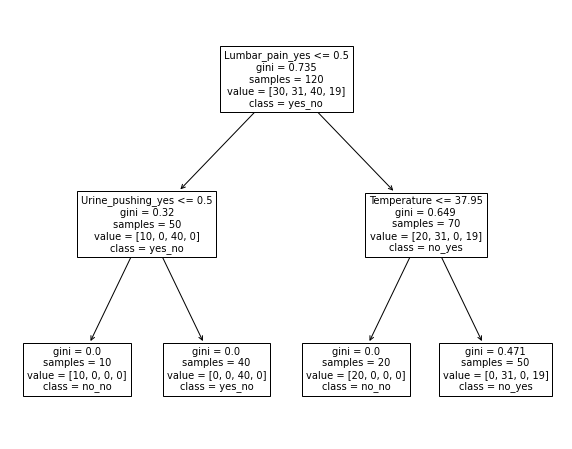

 if ( Lumbar_pain_yes <= 0.5 ) {
   if ( Urine_pushing_yes <= 0.5 ) {
     return no_no
   } else {
     return yes_no
   }
 } else {
   if ( Temperature <= 37.95000076293945 ) {
     return no_no
   } else {
     return no_yes
   }
 }


In [9]:
pruned_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=chosen_alpha)
pruned_tree.fit(X,y)

plt.figure(figsize=(10,8))
plot_tree(pruned_tree, feature_names=X.columns, class_names=pruned_tree.classes_)
plt.show()
tree_to_pseudo(pruned_tree, list(X.columns))

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
df2 = pd.read_csv("data/communities.data", header=None, na_values="?")

train = df2.iloc[:1495]
test = df2.iloc[1495:]

### (b) Missing values

In [11]:
train = train.iloc[:, 5:]
test = test.iloc[:, 5:]

imputer = SimpleImputer(strategy="mean")

train = pd.DataFrame(imputer.fit_transform(train), columns=train.columns, index=train.index)
test = pd.DataFrame(imputer.transform(test), columns=test.columns, index=test.index)

### (c) Plot a correlation matrix

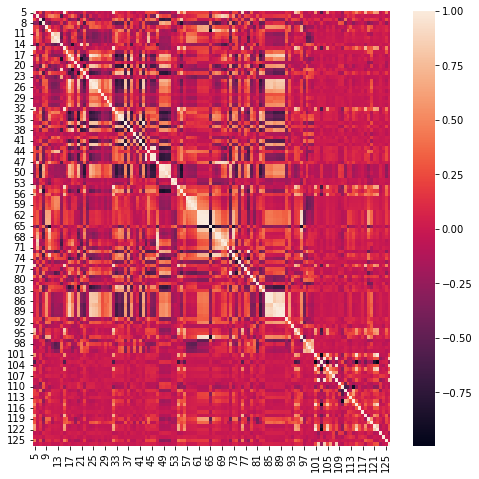

In [12]:
corr = train.iloc[:, :-1].corr()

plt.figure(figsize=(8,8))
sns.heatmap(corr)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [13]:
cv = train.iloc[:, :-1].std() / train.iloc[:, :-1].mean()
cv

5      2.241105
6      0.355800
7      1.428885
8      0.330213
9      1.359100
         ...   
122    0.743487
123    0.115739
124    0.362989
125    2.552946
126    0.326026
Length: 122, dtype: float64

### (e) Scatter plots and box plots for highest CV features

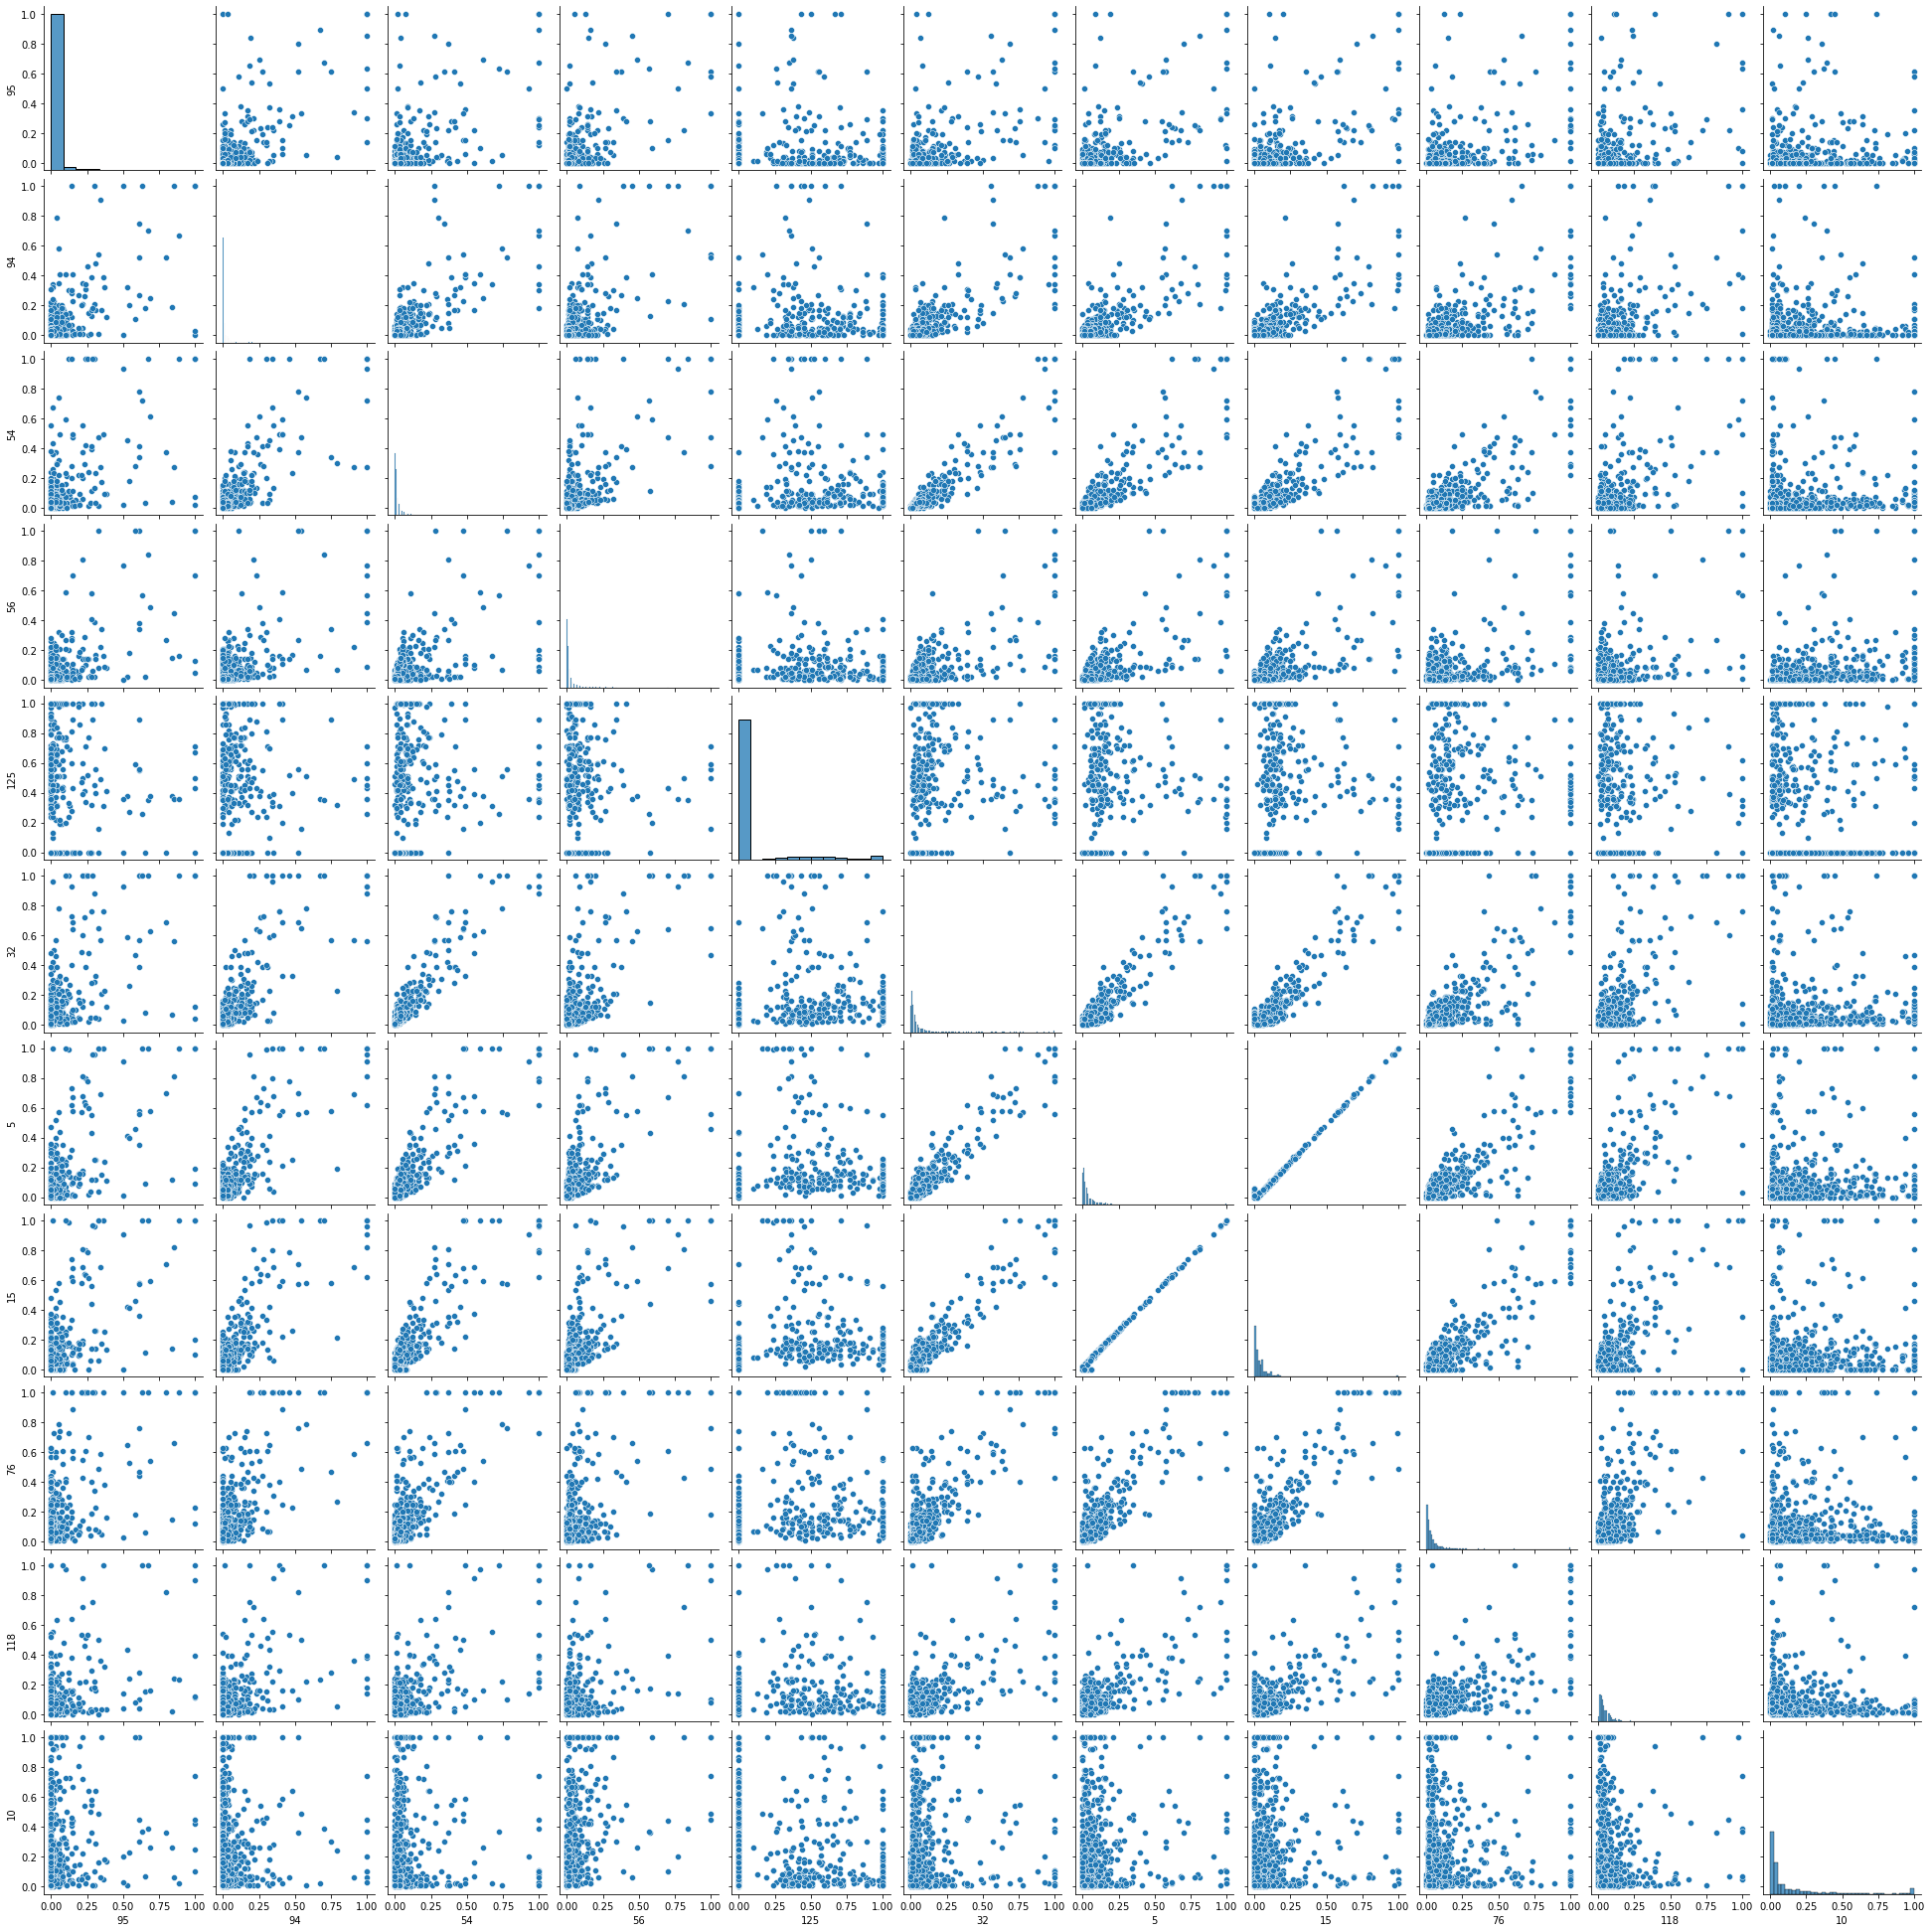

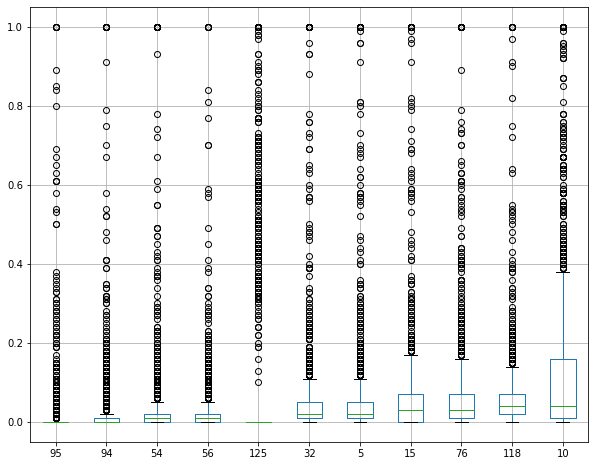

In [14]:
highest_cv = cv.sort_values(ascending=False).iloc[:int(np.sqrt(128))]
highest_cv

top = train[list(highest_cv.index)]

sns.pairplot(top)
plt.show()

top.boxplot(figsize=(10, 8))
plt.show()

We cannot draw conclusions about significant of those features, just by the scatter plots. Scatter plots show possible relationships and trends between features but they cannot determine statistical significance. 

### (f) Fit a linear model

In [15]:
X_train = train.iloc[:, :-1]
y_train = train.iloc[:, -1]
X_test = test.iloc[:, :-1]
y_test = test.iloc[:, -1]

X_train = sm.add_constant(X_train)
lin_reg = sm.OLS(y_train, X_train).fit()

X_test = sm.add_constant(X_test)
y_pred = lin_reg.predict(X_test)

test_error = mean_squared_error(y_test, y_pred)
print("Test Error:", test_error)

Test Error: 0.018141971135529997


### (g) Fit a ridge regression model

In [16]:
X_train_ridge = train.iloc[:, :-1]
X_test_ridge = test.iloc[:, :-1]

lambdas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

ridge_reg = RidgeCV(alphas=lambdas, cv=5)
ridge_reg.fit(X_train_ridge, y_train)

y_pred = ridge_reg.predict(X_test_ridge)

ridge_test_error = mean_squared_error(y_test, y_pred)

print("Best Lambda:", ridge_reg.alpha_)
print("Test Error:", ridge_test_error)

Best Lambda: 1.0
Test Error: 0.01773247499289665


### (h) Fit a LASSO model

In [17]:
X_train_lasso = train.iloc[:, :-1]
X_test_lasso = test.iloc[:, :-1]

cv = KFold(n_splits=5, shuffle=True, random_state=50)

lasso_reg = LassoCV(alphas=lambdas, cv=cv)
lasso_reg.fit(X_train_lasso, y_train)

y_pred = lasso_reg.predict(X_test_lasso)

lasso_test_error = mean_squared_error(y_test, y_pred)

print("Best Lambda:", lasso_reg.alpha_)
print("Test Error:", lasso_test_error)

variable_list = X_train_lasso.columns[lasso_reg.coef_ != 0]
print("Variable list:", list(variable_list))
print("Number of selected features:", len(variable_list))

Best Lambda: 0.0001
Test Error: 0.017786089519102124
Variable list: [7, 9, 11, 12, 14, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 36, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124, 125]
Number of selected features: 78


In [18]:
scaler = StandardScaler()

X_train_lasso_std = scaler.fit_transform(X_train_lasso)
X_test_lasso_std = scaler.transform(X_test_lasso)

lasso_reg_std = LassoCV(alphas=lambdas, cv=cv,max_iter=50000)
lasso_reg_std.fit(X_train_lasso_std, y_train)

y_pred_std = lasso_reg_std.predict(X_test_lasso_std)

lasso_test_error_std = mean_squared_error(y_test, y_pred_std)

print("Best Lambda:", lasso_reg_std.alpha_)
print("Test Error:", lasso_test_error_std)

variable_list_std = X_train_lasso.columns[lasso_reg_std.coef_ != 0]
print("Selected Features:", list(variable_list_std))
print("Number of selected features:", len(variable_list_std))

Best Lambda: 0.001
Test Error: 0.017758149260213713
Selected Features: [7, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 64, 66, 68, 72, 73, 74, 76, 77, 79, 80, 81, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]
Number of selected features: 68


Test error for LASSO model with raw features gave 0.017786089519102124 and selected 78 features, while test error for LASSO model with standardized features gave 0.017758149260213713 and selected 68 features. It can be seen that the LASSO model with standardized features performed slightly better with a lower test error and selecting fewer features, while still giving the similar prediction accuracy. 

### (i) Fit a PCR model

In [19]:
X_train_pcr = train.iloc[:, :-1]
X_test_pcr = test.iloc[:, :-1]

X_train_pcr.columns = X_train_pcr.columns.astype(str)
X_test_pcr.columns = X_test_pcr.columns.astype(str)

pcr = make_pipeline(
    StandardScaler(),
    PCA(),
    LinearRegression()
)

pcr_gridsearch = GridSearchCV(
    pcr,
    param_grid={"pca__n_components": range(1, X_train_pcr.shape[1] + 1)},
    cv=5,
    scoring="neg_mean_squared_error"
)

pcr_gridsearch.fit(X_train_pcr, y_train)

print("M, number of principal components:", pcr_gridsearch.best_params_["pca__n_components"])

M, number of principal components: 95


In [20]:
y_pred = pcr_gridsearch.predict(X_test_pcr)
pcr_test_error = mean_squared_error(y_test, y_pred)

print("PCR Test Error:", pcr_test_error)

PCR Test Error: 0.018398655802150894


### (j) Fit a boosting tree

In [21]:
X_train_xgb = train.iloc[:, :-1]
X_test_xgb = test.iloc[:, :-1]

xgb = XGBRegressor(random_state=42)

cv = KFold(n_splits=5, shuffle=True, random_state=50)

xgb_gridsearch = GridSearchCV(
    xgb,
    param_grid={"reg_alpha": range(0, 11)},
    cv=cv,
    scoring="neg_mean_squared_error"
)

xgb_gridsearch.fit(X_train_xgb, y_train)

print("Chosen alpha:", xgb_gridsearch.best_params_["reg_alpha"])

Chosen alpha: 2


In [22]:
y_pred = xgb_gridsearch.predict(X_test_xgb)
xgb_test_error = mean_squared_error(y_test, y_pred)

print("XGBoost Test Error:", xgb_test_error)

XGBoost Test Error: 0.01861293333755263
